In [ ]:
import pathlib
import random
import re
import warnings

import alifedata_phyloinformatics_convert as apc
from hstrat import _auxiliary_lib as hstrat_aux
import iplotx as ipx
import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import osf_fetch, percentileofscore_grouped

warnings.filterwarnings("ignore", category=DeprecationWarning)

OSF_SLUGS = ("kv2wy", "dz4n7", "ayht2", "u4qzk")
NUM_SITES = 16
ALPHA = 0.05
MAX_TREE_LEAVES = 4000
SEED = 1

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(


In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-10-23T17:25:23.488728+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 6.17.0-1022-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

seaborn                           : 0.13.2
alifedata_phyloinformatics_convert: 0.19.3
marimo                            : 0.23.2
re                                : 2.2.1
matplotlib                        : 3.10.9
pandas                            : 2.2.3
hstrat                            : 1.25.2
iplotx                            : 1.8.0
numpy                             : 2.1.2
scipy                             : 1.14.1
phyloframe                        : 0.12.2
polars                            : 1.36.1
teeplot                           : 1.4.2

```

In [ ]:
mo.md(f"""
# MLS Spectra Subgrid Fossils: Detectability by Population Size, Effect Size, and Site Class

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-19-mls-indiv-ratematched-fossils-reservoir`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-22-mls-spectra-subgrid-fossils`](https://github.com/mmore500/wse-async-ga/tree/master/wsclust/2026-10-22-mls-spectra-subgrid-fossils) and are hosted at {", ".join(f"<https://osf.io/{slug}>" for slug in OSF_SLUGS)}.
Each file is one run's minified hstrat-reconstructed phylogeny (`05-minify-phylo` output), for subgrid sizes 0 (i.e., the full grid), 27, 81, and 243.
Fossils were collected by reservoir sampling, so each fossil layer spans the whole run rather than one timepoint.

Runs use genome flavor `genome_mlsspectra_2026_10_22`, which carries three spectra of four sites each, with effect sizes $s_i \\in [0.05, 0.025, 0.01, 0.005]$, plus four neutral sites:

- **MLS** sites (`MLS`) are both within-host beneficial and between-host deleterious,
- **between-host deleterious** sites (`del`) carry only the between-host cost, and
- **within-host beneficial** sites (`ben`) carry only the within-host advantage.

The between-host cost is that a carrier immigrating into an extinct tile population is clobbered with probability $s_i$.
The within-host advantage is relative fitness $1 + s'_i$, with $s'_i = (1 + s_i)^{{\\log_2(N) / 25}} - 1$ rescaled to tile population size $N$.
Runs sweep subgrid size, where subgrids are blocks of tiles between which migration is disabled.

**Caveat:** these runs set `CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY` to 0, so tile populations never go extinct.
As the genome only accepts immigrants into extinct populations, immigration is a no-op and the between-host cost never applies: MLS sites behave as within-host beneficial sites and between-host deleterious sites behave as neutral sites (see site frequencies below), and tiles evolve in isolation regardless of subgrid size.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each focal (MLS, deleterious, or beneficial) site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\\alpha = {ALPHA}$, broken down by population size, site class, and effect size.
As a null calibration, the same screens are applied to each of the four neutral sites, against the other neutral sites.
""")

# MLS Spectra Subgrid Fossils: Detectability by Population Size, Effect Size, and Site Class

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-19-mls-indiv-ratematched-fossils-reservoir`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-22-mls-spectra-subgrid-fossils`](https://github.com/mmore500/wse-async-ga/tree/master/wsclust/2026-10-22-mls-spectra-subgrid-fossils) and are hosted at <https://osf.io/kv2wy>, <https://osf.io/dz4n7>, <https://osf.io/ayht2>, <https://osf.io/u4qzk>.
Each file is one run's minified hstrat-reconstructed phylogeny (`05-minify-phylo` output), for subgrid sizes 0 (i.e., the full grid), 27, 81, and 243.
Fossils were collected by reservoir sampling, so each fossil layer spans the whole run rather than one timepoint.

Runs use genome flavor `genome_mlsspectra_2026_10_22`, which carries three spectra of four sites each, with effect sizes $s_i \in [0.05, 0.025, 0.01, 0.005]$, plus four neutral sites:

- **MLS** sites (`MLS`) are both within-host beneficial and between-host deleterious,
- **between-host deleterious** sites (`del`) carry only the between-host cost, and
- **within-host beneficial** sites (`ben`) carry only the within-host advantage.

The between-host cost is that a carrier immigrating into an extinct tile population is clobbered with probability $s_i$.
The within-host advantage is relative fitness $1 + s'_i$, with $s'_i = (1 + s_i)^{\log_2(N) / 25} - 1$ rescaled to tile population size $N$.
Runs sweep subgrid size, where subgrids are blocks of tiles between which migration is disabled.

**Caveat:** these runs set `CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY` to 0, so tile populations never go extinct.
As the genome only accepts immigrants into extinct populations, immigration is a no-op and the between-host cost never applies: MLS sites behave as within-host beneficial sites and between-host deleterious sites behave as neutral sites (see site frequencies below), and tiles evolve in isolation regardless of subgrid size.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each focal (MLS, deleterious, or beneficial) site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\alpha = 0.05$, broken down by population size, site class, and effect size.
As a null calibration, the same screens are applied to each of the four neutral sites, against the other neutral sites.

## Get Data

In [ ]:
data_paths = [osf_fetch(slug) for slug in OSF_SLUGS]

downloading https://osf.io/kv2wy/download -> /tmp/kv2wy
size: 32614298 bytes
downloading https://osf.io/dz4n7/download -> /tmp/dz4n7
size: 29867532 bytes
downloading https://osf.io/ayht2/download -> /tmp/ayht2
size: 30963600 bytes
downloading https://osf.io/u4qzk/download -> /tmp/u4qzk
size: 31175533 bytes


In [ ]:
pl.scan_parquet(data_paths[0]).collect_schema()

Schema([('origin_time', Int16), ('dstream_rank', Int16), ('dstream_S', Int16), ('hstrat_differentia_bitwidth', UInt8), ('is_extant', Boolean), ('trait_focal', UInt16), ('layer', UInt8), ('layer_T', UInt8), ('row', UInt16), ('col', UInt16), ('subgrid', UInt8), ('subgrid_row', UInt8), ('subgrid_col', UInt8), ('config', String), ('file', Categorical), ('replicate', Categorical), ('sample_per_stratum', UInt32), ('genomeFlavor', Categorical), ('populationFlavor', Categorical), ('memcpyMajor', Categorical), ('globalSeed', UInt8), ('nCol', UInt16), ('nRow', UInt16), ('nWav', UInt8), ('nTrait', UInt8), ('nCycle', UInt16), ('nColSubgrid', UInt8), ('nRowSubgrid', UInt8), ('nonBlock', Boolean), ('tilePopSize', UInt16), ('tournSize', Float32), ('msec', Float32), ('tsc', UInt8), ('dstream_algo', Categorical), ('dstream_storage_bitoffset', UInt8), ('dstream_storage_bitwidth', UInt8), ('dstream_T_bitoffset', UInt8), ('dstream_T_bitwidth', UInt8), ('dstream_S_right', UInt8), ('flag_site_bitwidth', UInt8), ('flag_sites_bitoffset', UInt8), ('flag_sites_bitwidth', UInt8), ('mls_clobber_p_byte1_bit0', Float32), ('mls_selection_p_byte1_bit0', Float32), ('mls_clobber_p_byte1_bit1', Float32), ('mls_selection_p_byte1_bit1', Float32), ('mls_clobber_p_byte1_bit2', Float32), ('mls_selection_p_byte1_bit2', Float32), ('mls_clobber_p_byte1_bit3', Float32), ('mls_selection_p_byte1_bit3', Float32), ('deleterious_clobber_p_byte1_bit4', Float32), ('deleterious_selection_p_byte1_bit4', Float32), ('deleterious_clobber_p_byte1_bit5', Float32), ('deleterious_selection_p_byte1_bit5', Float32), ('deleterious_clobber_p_byte1_bit6', Float32), ('deleterious_selection_p_byte1_bit6', Float32), ('deleterious_clobber_p_byte1_bit7', Float32), ('deleterious_selection_p_byte1_bit7', Float32), ('beneficial_clobber_p_byte0_bit0', Float32), ('beneficial_selection_p_byte0_bit0', Float32), ('beneficial_clobber_p_byte0_bit1', Float32), ('beneficial_selection_p_byte0_bit1', Float32), ('beneficial_clobber_p_byte0_bit2', Float32), ('beneficial_selection_p_byte0_bit2', Float32), ('beneficial_clobber_p_byte0_bit3', Float32), ('beneficial_selection_p_byte0_bit3', Float32), ('_compconf_dummy', UInt8), ('CEREBRASLIB_TRAITLOGGER_NUM_BITS', UInt8), ('CEREBRASLIB_NONZERO_FIT_FUDGE', Float32), ('CEREBRASLIB_CLOBBER_IMMIGRANT_P', Float32), ('CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY', Float32), ('CEREBRASLIB_TRAITLOGGER_DILATION', UInt8), ('CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_HSTRAT_T_DILATION', UInt8), ('CEREBRASLIB_HSTRAT_DSTREAM_ALGO_NAME', Categorical), ('ASYNC_GA_FOSSIL_SAMPLING_MODE', Categorical), ('ASYNC_GA_GENOME_FLAVOR', Categorical), ('ASYNC_GA_POPULATION_FLAVOR', Categorical), ('ASYNC_GA_POPSIZE', UInt16), ('clade_size', UInt8), ('last_origin_time', Int16), ('trait_present', UInt16), ('ancestor_offset', Int16)])

In [ ]:
def _config_cols(names):
    return [
        name
        for name in names
        if name.startswith(("ASYNC_GA_", "CEREBRASLIB_", "dstream_algo"))
        or re.match(r"^(mls|deleterious|beneficial)_", name)
        or name
        in (
            "config",
            "genomeFlavor",
            "populationFlavor",
            "globalSeed",
            "nCol",
            "nRow",
            "nColSubgrid",
            "nRowSubgrid",
            "nWav",
            "nTrait",
            "nCycle",
            "tilePopSize",
            "tournSize",
            "replicate",
            "trait_focal",
            "dstream_S",
            "hstrat_differentia_bitwidth",
        )
    ]

_rows = []
for _path in data_paths:
    _lazy = pl.scan_parquet(_path).filter(pl.col("clade_size") > 0)
    # each file holds one run; check before taking its first row
    assert _lazy.select(pl.col("config").n_unique()).collect().item() == 1
    _rows.append(
        _lazy.select(_config_cols(_lazy.collect_schema().names()))
        .head(1)
        .collect()
    )
config_df = pl.concat(_rows, how="diagonal_relaxed").sort("nRowSubgrid")
assert config_df["config"].is_unique().all(), "expected one row per run"
assert (config_df["nRowSubgrid"] == config_df["nColSubgrid"]).all()
config_df.transpose(include_header=True)

column,column_0,column_1,column_2,column_3
str,str,str,str,str
"""dstream_S""","""128""","""128""","""128""","""128"""
"""hstrat_differentia_bitwidth""","""1""","""1""","""1""","""1"""
"""trait_focal""","""65295""","""65295""","""65295""","""65295"""
"""config""","""flavor=genome_mlsspectra_2026_…","""flavor=genome_mlsspectra_2026_…","""flavor=genome_mlsspectra_2026_…","""flavor=genome_mlsspectra_2026_…"
"""replicate""","""e71dada6-73ba-4247-aeda-a9ff0e…","""c91a31cf-aebc-47c3-babf-e44c7c…","""53ab9499-11e7-41fc-837c-977f4b…","""d6b8a963-6461-4575-bc92-808645…"
…,…,…,…,…
"""CEREBRASLIB_HSTRAT_DSTREAM_ALG…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…"
"""ASYNC_GA_FOSSIL_SAMPLING_MODE""","""reservoir""","""reservoir""","""reservoir""","""reservoir"""
"""ASYNC_GA_GENOME_FLAVOR""","""genome_mlsspectra_2026_10_22""","""genome_mlsspectra_2026_10_22""","""genome_mlsspectra_2026_10_22""","""genome_mlsspectra_2026_10_22"""


In [ ]:
# site class K's level-i site is flag byte B, bit b (trait site 8B + b),
# with clobber and selection probabilities (0 where a class lacks an effect)
_site_cols = [
    (int(B) * 8 + int(b), kind, what, col)
    for col in config_df.columns
    for kind, what, B, b in re.findall(
        r"^(mls|deleterious|beneficial)_(clobber|selection)"
        r"_p_byte(\d+)_bit(\d+)$",
        col,
    )
]
effect_sizes = (
    pd.DataFrame(
        [
            {
                "config": row["config"],
                "site": site,
                "kind": kind,
                f"{what}_p": row[col],
                "clobber_scale": row["CEREBRASLIB_CLOBBER_IMMIGRANT_P"],
                "popsize": row["ASYNC_GA_POPSIZE"],
            }
            for row in config_df.iter_rows(named=True)
            for site, kind, what, col in _site_cols
        ],
    )
    .groupby(["config", "site"], as_index=False)
    .first()
)
# recover base effect size s_i from clobber probability or, for
# within-host beneficial sites, by inverting the selection rescaling
# s'_i = (1 + s_i) ^ (log2(N) / 25) - 1
effect_sizes["effect_size"] = np.where(
    effect_sizes["kind"] == "beneficial",
    (1 + effect_sizes["selection_p"])
    ** (25 / np.log2(effect_sizes["popsize"]))
    - 1,
    effect_sizes["clobber_p"] / effect_sizes["clobber_scale"],
).round(6)
# effect sizes are the same across runs and site classes
assert (effect_sizes.groupby("site")["effect_size"].nunique() == 1).all()
assert (
    effect_sizes.groupby("kind")["effect_size"]
    .apply(lambda x: tuple(sorted(x.unique())))
    .nunique()
    == 1
)
focal_sites = sorted(effect_sizes["site"].unique().tolist())
_focal_mask = sum(1 << site for site in focal_sites)
assert (config_df["trait_focal"] == _focal_mask).all(), "focal mismatch"
background_sites = [
    site for site in range(NUM_SITES) if site not in focal_sites
]
# every neutral site serves as a null control, against the others
control_sites = background_sites

_kind_labels = {"mls": "MLS", "deleterious": "del", "beneficial": "ben"}
_site_info = effect_sizes.groupby("site")[["kind", "effect_size"]].first()
site_labels = pd.Series(
    {
        site: (
            f"{_kind_labels[_site_info.loc[site, 'kind']]}"
            f" s={_site_info.loc[site, 'effect_size']:g}"
            if site in focal_sites
            else "Neutral"
        )
        for site in range(NUM_SITES)
    },
)
mutation_order = [
    f"{_kind_labels[_kind]} s={_s:g}"
    for _kind in _kind_labels
    for _s in sorted(_site_info["effect_size"].unique(), reverse=True)
] + ["Neutral"]
effect_sizes

,config,site,kind,clobber_p,clobber_scale,popsize,selection_p,effect_size
0,flavor=genome_mlsspectra_2026_10_22+subgrid=0+seed=1,0,beneficial,0.000,1.0,1133,0.019998,0.050
1,flavor=genome_mlsspectra_2026_10_22+subgrid=0+seed=1,1,beneficial,0.000,1.0,1133,0.010072,0.025
2,flavor=genome_mlsspectra_2026_10_22+subgrid=0+seed=1,2,beneficial,0.000,1.0,1133,0.004046,0.010
3,flavor=genome_mlsspectra_2026_10_22+subgrid=0+seed=1,3,beneficial,0.000,1.0,1133,0.002026,0.005
4,flavor=genome_mlsspectra_2026_10_22+subgrid=0+seed=1,8,mls,0.050,1.0,1133,0.019998,0.050
...,...,...,...,...,...,...,...,...
43,flavor=genome_mlsspectra_2026_10_22+subgrid=81+seed=3,11,mls,0.005,1.0,1133,0.002026,0.005
44,flavor=genome_mlsspectra_2026_10_22+subgrid=81+seed=3,12,deleterious,0.050,1.0,1133,0.000000,0.050
45,flavor=genome_mlsspectra_2026_10_22+subgrid=81+seed=3,13,deleterious,0.025,1.0,1133,0.000000,0.025
46,flavor=genome_mlsspectra_2026_10_22+subgrid=81+seed=3,14,deleterious,0.010,1.0,1133,0.000000,0.010


## Prep Data

Minification collapsed each maximal clade of genomes sharing identical traits onto its root, which became a leaf; `clade_size` gives the number of fossil genomes it represents, and `last_origin_time` the latest among them.
Genome counts below weight leaves by `clade_size`.

Fossil layer 0 samples the initial population, at `origin_time == -1` before any lineage history accumulated (as in `2026-10-15-mls-strong-fossils`), so these genomes are dropped (collapsed leaves are kept if any member has `last_origin_time >= 0`).
Some roots have no `origin_time`; as roots can be no later than the run start, it is set to -1.
Lineages without retained leaves are pruned and unifurcations collapsed.

In [ ]:
# runs are independent, so each run's file is loaded, checked, summarized,
# and pruned separately to bound memory use
_pruned, _tips, _site_freqs, _times = [], [], [], []
_offset = 0
for _path in data_paths:
    # unminify: rows are in depth-first order, with id = row index
    _raw = (
        pl.read_parquet(
            _path,
            columns=[
                "ancestor_offset",
                "origin_time",
                "last_origin_time",
                "clade_size",
                "trait_present",
                "config",
                "layer",
                "subgrid",
            ],
        )
        .with_row_index("id")
        .with_columns(
            pl.col("id").cast(pl.Int64),
            ancestor_id=(
                pl.col("id").cast(pl.Int64)
                - pl.col("ancestor_offset").cast(pl.Int64)
            ),
            config=pl.col("config").cast(pl.String),
            # the full-grid run also fills subgrid (0) on inner nodes
            subgrid=pl.when(pl.col("clade_size") > 0).then(
                pl.col("subgrid").cast(pl.Int64)
            ),
            trait_present=pl.col("trait_present").cast(pl.Int64),
        )
        .drop("ancestor_offset")
        .to_pandas()
    )

    # some roots lack origin_time; roots can be no later than run start
    _no_time = _raw["origin_time"].isna()
    assert (
        _raw.loc[_no_time, "ancestor_id"] == _raw.loc[_no_time, "id"]
    ).all()
    _raw["origin_time"] = _raw["origin_time"].fillna(-1)
    _raw["last_origin_time"] = _raw["last_origin_time"].fillna(
        _raw["origin_time"]
    )

    _is_genome = _raw["clade_size"] > 0
    assert (_is_genome == _raw["trait_present"].notna()).all()
    assert (_is_genome == _raw["subgrid"].notna()).all()
    assert _raw["config"].notna().all()
    assert (_raw["ancestor_id"] <= _raw["id"]).all()
    _has_child = np.zeros(len(_raw), dtype=bool)
    _has_child[_raw["ancestor_id"]] = True
    _has_child[_raw["ancestor_id"] == _raw["id"]] = False
    # collapsed monomorphic clades and fossil genomes are leaves
    assert not (_has_child & _is_genome).any()

    _tips.append(
        _raw[_is_genome]
        .groupby("config")
        .agg(
            num_leaves=("id", "size"),
            num_genomes=("clade_size", "sum"),
            clade_size_mean=("clade_size", "mean"),
            clade_size_max=("clade_size", "max"),
            num_layers=("layer", "nunique"),
            origin_time_min=("origin_time", "min"),
            last_origin_time_max=("last_origin_time", "max"),
            negative_origin_frac=(
                "last_origin_time",
                lambda x: (x < 0).mean(),
            ),
        )
        .assign(num_nodes=len(_raw)),
    )
    _times.append(
        _raw.assign(is_genome=_is_genome)
        .groupby(["config", "is_genome"])[
            ["origin_time", "last_origin_time"]
        ]
        .describe(),
    )

    _extant = _is_genome & (_raw["last_origin_time"] >= 0)
    _weights = _raw.loc[_extant, "clade_size"].to_numpy(dtype=float)
    _present = _raw.loc[_extant, "trait_present"].to_numpy(dtype=np.uint64)
    _site_freqs.append(
        pd.Series(
            {
                f"site {site} ({site_labels[site]})": (
                    ((_present >> np.uint64(site)) & np.uint64(1))
                    * _weights
                ).sum()
                / _weights.sum()
                for site in range(NUM_SITES)
            },
            name=_raw["config"].iloc[0],
        ),
    )

    _part = (
        _raw.assign(extant=_extant)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
        .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_mark_leaves, mutate=True)
        .reset_index(drop=True)
    )
    del _raw
    assert (_part["is_leaf"] == _part["extant"]).all()
    _part = _part.drop(columns=["extant", "layer"])
    # offset ids so they are unique across runs
    _part["id"] += _offset
    _part["ancestor_id"] += _offset
    _offset += len(_part)
    _pruned.append(_part)
    del _part

phylo_pruned = pd.concat(_pruned, ignore_index=True)
del _pruned
assert (phylo_pruned["id"] == np.arange(len(phylo_pruned))).all()
tips_summary = pd.concat(_tips).T
times_summary = pd.concat(_times).T
# genome-weighted fraction of fossil genomes carrying each site, by run
site_frequencies = pd.DataFrame(_site_freqs).T
phylo_pruned.info()

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/phyloframe/legacy/_alifestd_assign_contiguous_ids.py:41: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  [reassignment[ancestor_id] for ancestor_id in ancestor_ids]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15368398 entries, 0 to 15368397
Data columns (total 9 columns):
 #   Column            Dtype  
---  ------            -----  
 0   id                int64  
 1   origin_time       float64
 2   last_origin_time  float64
 3   clade_size        uint8  
 4   trait_present     float64
 5   config            object 
 6   subgrid           float64
 7   ancestor_id       int64  
 8   is_leaf           bool   
dtypes: bool(1), float64(4), int64(2), object(1), uint8(1)
memory usage: 850.1+ MB


In [ ]:
tips_summary

config,flavor=genome_mlsspectra_2026_10_22+subgrid=0+seed=1,flavor=genome_mlsspectra_2026_10_22+subgrid=27+seed=2,flavor=genome_mlsspectra_2026_10_22+subgrid=81+seed=3,flavor=genome_mlsspectra_2026_10_22+subgrid=243+seed=4
num_leaves,2.175583e+06,2.084091e+06,2.060253e+06,2.078348e+06
num_genomes,3.999989e+06,3.973200e+06,3.995700e+06,3.999600e+06
clade_size_mean,1.838583e+00,1.906443e+00,1.939422e+00,1.924413e+00
clade_size_max,3.700000e+01,3.600000e+01,7.700000e+01,8.800000e+01
num_layers,4.300000e+01,4.300000e+01,3.800000e+01,4.400000e+01
origin_time_min,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00
last_origin_time_max,7.955000e+03,7.849000e+03,7.999000e+03,8.001000e+03
negative_origin_frac,4.067415e-02,4.159175e-02,4.896632e-02,4.206803e-02
num_nodes,4.136844e+06,3.814709e+06,3.878914e+06,3.901417e+06


In [ ]:
times_summary

config flavor=genome_mlsspectra_2026_10_22+subgrid=0+seed=1 flavor=genome_mlsspectra_2026_10_22+subgrid=27+seed=2 flavor=genome_mlsspectra_2026_10_22+subgrid=81+seed=3 flavor=genome_mlsspectra_2026_10_22+subgrid=243+seed=4 is_genome False True False True False True False True origin_time count 1.961261e+06 2.175583e+06 1.730618e+06 2.084091e+06 1.818661e+06 2.060253e+06 1.823069e+06 2.078348e+06 mean 1.239134e+03 2.443412e+03 1.162901e+03 2.336318e+03 1.210514e+03 2.441531e+03 1.277130e+03 2.470944e+03 std 1.348624e+03 1.937604e+03 1.436187e+03 1.965637e+03 1.424724e+03 1.911451e+03 1.447174e+03 1.988022e+03 min -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 25% 2.540000e+02 8.150000e+02 7.800000e+01 6.070000e+02 1.260000e+02 8.390000e+02 1.900000e+02 7.790000e+02 ... ... ... ... ... ... ... ... ... ... last_origin_time min -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 25% 2.540000e+02 1.127000e+03 7.800000e+01 1.161000e+03 1.260000e+02 1.357000e+03 1.900000e+02 1.143000e+03 50% 7.660000e+02 3.117000e+03 4.460000e+02 3.257000e+03 5.740000e+02 3.335000e+03 7.020000e+02 3.151000e+03 75% 1.790000e+03 5.407000e+03 1.917000e+03 5.415000e+03 1.919000e+03 5.359000e+03 1.905000e+03 5.353000e+03 max 7.631000e+03 7.955000e+03 7.551000e+03 7.849000e+03 7.678000e+03 7.999000e+03 7.806000e+03 8.001000e+03 16 rows × 8 columns

In [ ]:
# render in full; marimo's default display truncates to ten rows
mo.Html(site_frequencies.to_html(float_format="{:.5f}".format))

,flavor=genome_mlsspectra_2026_10_22+subgrid=0+seed=1,flavor=genome_mlsspectra_2026_10_22+subgrid=27+seed=2,flavor=genome_mlsspectra_2026_10_22+subgrid=81+seed=3,flavor=genome_mlsspectra_2026_10_22+subgrid=243+seed=4
site 0 (ben s=0.05),0.12921,0.12742,0.12998,0.13012
site 1 (ben s=0.025),0.06609,0.06559,0.06641,0.06645
site 2 (ben s=0.01),0.02587,0.02534,0.02590,0.02632
site 3 (ben s=0.005),0.01492,0.01491,0.01481,0.01511
site 4 (Neutral),0.00663,0.00664,0.00681,0.00679
site 5 (Neutral),0.00669,0.00658,0.00681,0.00678
site 6 (Neutral),0.00674,0.00681,0.00694,0.00679
site 7 (Neutral),0.00687,0.00668,0.00672,0.00686
site 8 (MLS s=0.05),0.13172,0.13047,0.13253,0.13285
site 9 (MLS s=0.025),0.06536,0.06526,0.06593,0.06616


MLS site frequencies match those of within-host beneficial sites at the same effect size, and between-host deleterious site frequencies match neutral site frequencies, consistent with the between-host cost never applying in these runs (see caveat above).

## Split Populations

Subgrids share no migration, so no true common ancestry links genomes from different subgrids (or runs); each run's tree was reconstructed independently, but hstrat reconstruction can still join unrelated lineages at spurious deep nodes.
To analyze each population (run × subgrid) independently, nodes whose descendant leaves span more than one population are deleted, making each maximal single-population clade a root.
Each population's forest is then analyzed separately.

Edge subgrids are truncated by the grid boundary (e.g., 755 columns is not a multiple of 27), so only full-size subgrids are retained.

In [ ]:
_config_codes = {
    config: i for i, config in enumerate(config_df["config"].to_list())
}
_is_leaf = phylo_pruned["is_leaf"].to_numpy()
_pop_code = np.where(
    _is_leaf,
    phylo_pruned["config"].map(_config_codes).to_numpy(dtype=np.int64)
    * 2**32
    + phylo_pruned["subgrid"].fillna(0).to_numpy(dtype=np.int64),
    -1,
)
_pure = pfl.alifestd_mask_monomorphic_clades_asexual(
    phylo_pruned[["id", "ancestor_id"]],
    trait_mask=_is_leaf,
    trait_values=_pop_code,
)["alifestd_mask_monomorphic_clades_asexual"].to_numpy()
_ancestor_ids = phylo_pruned["ancestor_id"].to_numpy()
_is_root = _ancestor_ids == phylo_pruned["id"].to_numpy()
split_summary = pd.Series(
    {
        "num_nodes": len(phylo_pruned),
        "num_multipopulation_nodes": int((~_pure).sum()),
        "num_roots_before": int(_is_root.sum()),
        "num_roots_after": int(
            (_pure & (_is_root | ~_pure[_ancestor_ids])).sum()
        ),
    },
).to_frame("value")

_phylo_split = (
    phylo_pruned[_pure]
    .assign(
        ancestor_id=np.where(
            _pure[_ancestor_ids], _ancestor_ids, phylo_pruned["id"]
        )[_pure],
        pop_code=_pop_code[_pure],
    )
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .reset_index(drop=True)
)
_root_pops = (
    _phylo_split.loc[_phylo_split["is_leaf"]]
    .groupby("root_id")["pop_code"]
    .agg(["first", "nunique"])
)
assert (_root_pops["nunique"] == 1).all()
_phylo_split["pop_code"] = _phylo_split["root_id"].map(_root_pops["first"])
assert (_phylo_split["pop_code"] >= 0).all()
_phylo_split["config"] = _phylo_split.groupby("pop_code")[
    "config"
].transform("first")
_phylo_split["subgrid"] = (_phylo_split["pop_code"] % 2**32).astype(int)
# the split tree is kept only within this cell, to bound memory use
_config = config_df.select(
    "config", "nRow", "nCol", "nRowSubgrid", "nColSubgrid", "tilePopSize"
).to_pandas()
_leaves = _phylo_split[_phylo_split["is_leaf"]]
populations = (
    _leaves.groupby("pop_code")
    .agg(
        config=("config", "first"),
        subgrid=("subgrid", "first"),
        num_leaves=("id", "size"),
        num_genomes=("clade_size", "sum"),
        num_roots=("root_id", "nunique"),
    )
    .reset_index()
    .merge(_config, on="config")
)
_has_subgrids = populations["nRowSubgrid"] > 0
_nrow_sub = populations["nRowSubgrid"].where(
    _has_subgrids, populations["nRow"]
)
_ncol_sub = populations["nColSubgrid"].where(
    _has_subgrids, populations["nCol"]
)
_nsub_cols = -(-populations["nCol"] // _ncol_sub)
_sub_row = populations["subgrid"] // _nsub_cols
_sub_col = populations["subgrid"] % _nsub_cols
populations["is_full_size"] = (
    (_sub_row + 1) * _nrow_sub <= populations["nRow"]
) & ((_sub_col + 1) * _ncol_sub <= populations["nCol"])
populations["pop_tiles"] = (_nrow_sub * _ncol_sub).astype(int)
populations["pop_size"] = [
    f"{r}x{c}"
    for r, c in zip(_nrow_sub.astype(int), _ncol_sub.astype(int))
]
pop_size_order = (
    populations.sort_values("pop_tiles")["pop_size"].unique().tolist()
)
del _leaves
_full_pops = populations.loc[populations["is_full_size"], "pop_code"]
phylo = (
    _phylo_split[_phylo_split["pop_code"].isin(_full_pops)]
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .pipe(pfl.alifestd_mark_num_leaves_asexual, mutate=True)
    .reset_index(drop=True)
)
phylo["trait_present"] = (
    phylo["trait_present"].fillna(0).to_numpy(dtype=np.uint64)
)
del _phylo_split
_is_leaf = phylo["is_leaf"].to_numpy()
phylo["num_genomes"] = pfl.alifestd_calc_clade_trait_count_asexual(
    phylo[["id", "ancestor_id"]],
    # passing counts rather than a mask sums genomes over descendants
    trait_mask=np.where(_is_leaf, phylo["clade_size"], 0),
)
# collapsed leaves' clades last until their latest member genome
phylo["max_descendant_origin_time"] = (
    phylo[["id", "ancestor_id"]]
    .assign(
        origin_time=np.where(
            _is_leaf, phylo["last_origin_time"], phylo["origin_time"]
        ),
    )
    .pipe(pfl.alifestd_mark_max_descendant_origin_time_asexual)[
        "max_descendant_origin_time"
    ]
    .to_numpy()
)
phylo = phylo.pipe(pfl.alifestd_mark_clade_duration_asexual, mutate=True)
phylo.info()

/tmp/marimo_5318/__marimo__cell_iLit_.py:73: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _nrow_sub = populations["nRowSubgrid"].where(
/tmp/marimo_5318/__marimo__cell_iLit_.py:76: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _ncol_sub = populations["nColSubgrid"].where(


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15368398 entries, 0 to 15368397
Data columns (total 16 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   id                          int64  
 1   origin_time                 float64
 2   last_origin_time            float64
 3   clade_size                  uint8  
 4   trait_present               uint64 
 5   config                      object 
 6   subgrid                     int64  
 7   ancestor_id                 int64  
 8   is_leaf                     bool   
 9   pop_code                    int64  
 10  is_root                     bool   
 11  root_id                     int64  
 12  num_leaves                  int64  
 13  num_genomes                 int64  
 14  max_descendant_origin_time  float64
 15  clade_duration              float64
dtypes: bool(2), float64(4), int64(7), object(1), uint64(1), uint8(1)
memory usage: 1.5+ GB


In [ ]:
split_summary

,value
num_nodes,15368398
num_multipopulation_nodes,0
num_roots_before,1413261
num_roots_after,1413261


In [ ]:
populations.groupby(["pop_size", "is_full_size"], sort=False).agg(
    num_populations=("pop_code", "size"),
    pop_tiles=("pop_tiles", "first"),
    tile_pop_size=("tilePopSize", "first"),
    num_leaves_median=("num_leaves", "median"),
    num_genomes_median=("num_genomes", "median"),
    num_genomes_min=("num_genomes", "min"),
    num_genomes_max=("num_genomes", "max"),
    num_roots_median=("num_roots", "median"),
).T

pop_size,1170x755,27x27,81x81,243x243
is_full_size,True,True,True,True
num_populations,1.0,1232.0,150.0,20.0
pop_tiles,883350.0,729.0,6561.0,59049.0
tile_pop_size,1133.0,1133.0,1133.0,1133.0
num_leaves_median,2087093.0,1628.0,13449.0,110386.5
num_genomes_median,3911093.0,3155.0,25965.0,195611.5
num_genomes_min,3911093.0,3150.0,25952.0,195568.0
num_genomes_max,3911093.0,3162.0,25981.0,195634.0
num_roots_median,248012.0,421.0,2225.0,16797.5


In [ ]:
_bad = ~(phylo["clade_duration"] >= 0)
phylo.loc[
    _bad,
    [
        "id",
        "ancestor_id",
        "is_leaf",
        "origin_time",
        "last_origin_time",
        "max_descendant_origin_time",
        "clade_duration",
        "clade_size",
        "pop_code",
    ],
].describe(include="all").T.assign(num_bad=int(_bad.sum()))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max,num_bad
id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
ancestor_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
is_leaf,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
last_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
max_descendant_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_duration,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_size,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
pop_code,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [ ]:
mo.md(f"""
## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most {MAX_TREE_LEAVES} leaves is drawn.
Diamonds mark tips carrying any focal (MLS, deleterious, or beneficial) mutation; circles mark tips carrying any neutral (background) mutation.
""")

## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most 4000 leaves is drawn.
Diamonds mark tips carrying any focal (MLS, deleterious, or beneficial) mutation; circles mark tips carrying any neutral (background) mutation.

teeplots/2026-10-22-mls-spectra-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=5572380+viz=tree+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=5572380+viz=tree+ext=.png


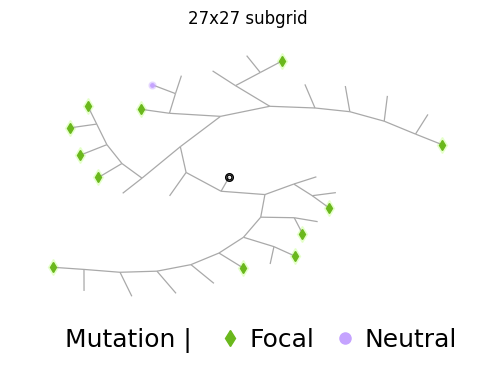

teeplots/2026-10-22-mls-spectra-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=9004511+viz=tree+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=9004511+viz=tree+ext=.png


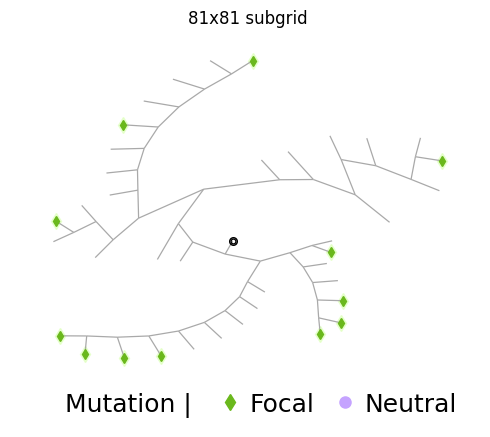

teeplots/2026-10-22-mls-spectra-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=14208419+viz=tree+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=14208419+viz=tree+ext=.png


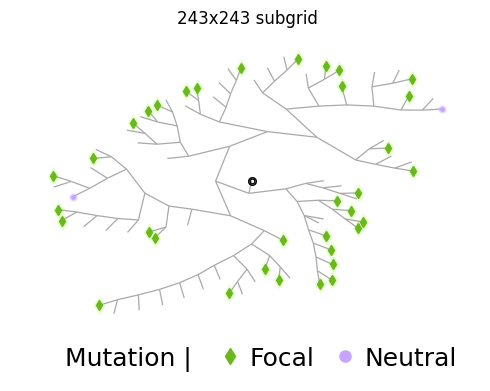

teeplots/2026-10-22-mls-spectra-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=3922906+viz=tree+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=3922906+viz=tree+ext=.png


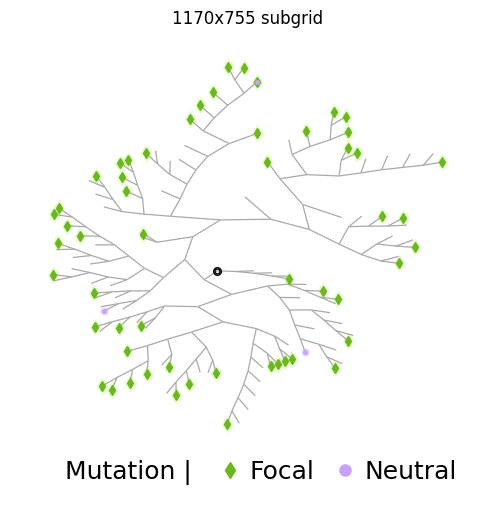

In [ ]:
_focal_mask = np.uint64(sum(1 << site for site in focal_sites))
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
_is_leaf = phylo["is_leaf"].to_numpy()
_phylo = phylo.assign(
    has_mls=np.where(
        _is_leaf, (_trait_present & _focal_mask) != 0, np.nan
    ),
    has_neutral=np.where(
        _is_leaf, (_trait_present & ~_focal_mask) != 0, np.nan
    ),
)
_roots = _phylo.loc[_phylo["is_root"], ["id", "num_leaves", "pop_code"]]
_roots = _roots[_roots["num_leaves"] <= MAX_TREE_LEAVES]
_rng = random.Random(SEED)
for _pop_size in pop_size_order:
    _pops = populations.loc[
        populations["is_full_size"]
        & (populations["pop_size"] == _pop_size)
        & populations["pop_code"].isin(_roots["pop_code"]),
        "pop_code",
    ].tolist()
    if not _pops:
        continue
    _pop_code = _rng.choice(_pops)
    _root_id = (
        _roots.loc[_roots["pop_code"] == _pop_code]
        .nlargest(1, "num_leaves")["id"]
        .item()
    )

    _subtree = (
        _phylo[_phylo["root_id"] == _root_id]
        .pipe(pfl.alifestd_assign_contiguous_ids)
        .pipe(pfl.alifestd_try_add_ancestor_list_col)
    )
    _tree = apc.alife_dataframe_to_dendropy_tree(
        _subtree,
        setattrs=["has_mls", "has_neutral"],
    )
    with hstrat_aux.RngStateContext(6):
        _tree.ladderize()
        _tree.reorder(key=lambda *args: max(random.random(), 0.89))

    with tp.teed(
        ipx.plotting.tree,
        _tree,
        aspect=0.7,
        edge_color="darkgray",
        edge_linewidth=0.9,
        ladderize=True,
        layout="radial",
        layout_angular=True,
        layout_start=0.25,
        margins=0,
        teeplot_outattrs={"pop_size": _pop_size, "root_id": _root_id},
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _teed:
        plt.gcf().set_size_inches(6, 6)

        for _n, (_x, _y) in _teed.get_layout().T.items():
            _x_, _y_ = _x * np.cos(_y), _x * np.sin(_y)
            if _n.has_mls == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=8,
                    color="#E2FFC4",
                    alpha=0.8,
                    zorder=0,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=5,
                    color="#6AB81C",
                    alpha=1,
                    zorder=2,
                )
            if _n.has_neutral == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=5,
                    color="#C5A3FF",
                    alpha=0.3,
                    zorder=1,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=2.5,
                    color="#C5A3FF",
                    alpha=1.0,
                    zorder=3,
                )
            if _n is _tree.seed_node:
                for _size in 3.5, 5.5:
                    plt.plot(
                        _x_,
                        _y_,
                        "o",
                        markersize=_size,
                        color="black",
                        alpha=1,
                        fillstyle="none",
                    )

        plt.gca().margins(x=0.02, y=0.02)
        plt.title(f"{_pop_size} subgrid")

        (_h0,) = plt.plot(
            [], [], "d", markersize=0, color="#FFFFFF", label="Mutation | "
        )
        (_h1,) = plt.plot(
            [], [], "d", markersize=8, color="#6AB81C", label="Focal"
        )
        (_h2,) = plt.plot(
            [], [], "o", markersize=8, color="#C5A3FF", label="Neutral"
        )
        plt.legend(
            handles=[_h0, _h1, _h2],
            loc="upper center",
            bbox_to_anchor=(0.48, 0.05),
            frameon=False,
            ncol=4,
            fontsize=18,
            columnspacing=0.2,
            handletextpad=-0.2,
        )
    plt.close("all")

## Screen Mutation-defined Clades

MDCs are identified for each of the 16 trait sites by Fitch maximum parsimony over leaf states (root state assumed absent), as in `2026-10-15-mls-strong-fossils`.
Because each population's trees share no nodes with other populations', one screen over the whole forest is equivalent to screening each population separately.

The screen uses phyloframe's `alifestd_screen_trait_defined_clades_fitch_asexual`, which requires phyloframe >= 0.12.2 to run in linear time at this data size.

MDC size is measured as `carriers`, the number of descendant fossil genomes carrying the mutation; `num_genomes` counts all descendant fossil genomes.
`carrier_frac` is the carrier fraction among descendant genomes, and `is_terminal` marks MDCs arising on a terminal branch to a single genome (MDC node is an uncollapsed leaf).
`clade_duration` spans from MDC origin to its latest descendant fossil.

In [ ]:
_work = phylo[["id", "ancestor_id"]].copy()
_is_leaf = phylo["is_leaf"].to_numpy()
_clade_size = phylo["clade_size"].fillna(0).to_numpy(dtype=np.int64)
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
mdc_ids = {}
mdc_carriers = {}
for _site in mo.status.progress_bar(range(NUM_SITES)):
    _has = ((_trait_present >> np.uint64(_site)) & np.uint64(1)) != 0
    _mask = _work.pipe(
        pfl.alifestd_screen_trait_defined_clades_fitch_asexual,
        mutate=True,
        mask_trait_absent=_is_leaf & ~_has,
        mask_trait_present=_is_leaf & _has,
    ).astype(bool)
    # passing counts rather than a mask sums carriers over descendants
    _carriers = _work.pipe(
        pfl.alifestd_calc_clade_trait_count_asexual,
        mutate=True,
        trait_mask=np.where(_is_leaf & _has, _clade_size, 0),
    )
    mdc_ids[_site] = np.flatnonzero(_mask)
    mdc_carriers[_site] = _carriers[_mask]

In [ ]:
_cols = [
    "id",
    "origin_time",
    "num_genomes",
    "clade_duration",
    "is_leaf",
    "clade_size",
    "pop_code",
]
mdcs = pd.concat(
    [
        phylo.loc[ids, _cols].assign(
            site=site,
            is_focal=site in focal_sites,
            is_control=site in control_sites,
            carriers=mdc_carriers[site],
        )
        for site, ids in mdc_ids.items()
    ],
    ignore_index=True,
)
mdcs["is_terminal"] = mdcs["is_leaf"] & (mdcs["clade_size"] == 1)
mdcs["carrier_frac"] = mdcs["carriers"] / mdcs["num_genomes"]
mdcs["mutation"] = mdcs["site"].map(site_labels)
mdcs = mdcs.drop(columns=["is_leaf", "clade_size"]).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
mdcs.groupby(["pop_size", "mutation"], sort=False).agg(
    num_mdcs=("id", "size"),
    carriers_mean=("carriers", "mean"),
    carriers_singleton_frac=("carriers", lambda x: (x == 1).mean()),
    carrier_frac_mean=("carrier_frac", "mean"),
    terminal_frac=("is_terminal", "mean"),
    clade_duration_mean=("clade_duration", "mean"),
).unstack("pop_size")

num_mdcs carriers_mean carriers_singleton_frac ... carrier_frac_mean terminal_frac clade_duration_mean pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation ben s=0.05 177277 165515 166634 161580 2.851419 2.833453 2.965961 3.083618 0.290715 0.273395 ... 0.990282 0.983956 0.290715 0.273395 0.285584 0.336997 1745.849462 1684.910201 1723.284738 1638.448781 ben s=0.025 95175 89841 89204 87208 2.716028 2.734653 2.851195 2.933573 0.306078 0.291114 ... 0.993459 0.988709 0.306078 0.291114 0.301556 0.356653 1619.336349 1591.259102 1610.306690 1501.966127 ben s=0.01 39694 37333 37413 36916 2.547211 2.566603 2.668297 2.763951 0.344762 0.336941 ... 0.995562 0.992773 0.344762 0.336941 0.347206 0.396007 1467.758503 1440.894838 1461.143239 1339.142404 ben s=0.005 24169 23084 22812 22118 2.413629 2.447496 2.511178 2.643639 0.390417 0.381910 ... 0.996937 0.993951 0.390417 0.381910 0.392294 0.436613 1338.406637 1327.719416 1317.051289 1226.488561 Neutral 48358 46071 46368 45001 2.174366 2.210501 2.271200 2.345903 0.484656 0.474442 ... 0.997621 0.996063 0.484656 0.474442 0.489626 0.521100 1321.988172 1354.227388 1334.541969 1198.352992 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... MLS s=0.005 23862 22593 22627 21985 2.415849 2.423892 2.519026 2.640528 0.395482 0.382198 ... 0.996518 0.993725 0.395482 0.382198 0.398064 0.437344 1343.327215 1315.156110 1315.410041 1224.539823 del s=0.05 11955 11444 11543 11079 2.176579 2.192765 2.288487 2.333153 0.488080 0.482087 ... 0.997623 0.995361 0.488080 0.482087 0.482370 0.526040 1327.317942 1328.610451 1341.885645 1201.827421 del s=0.025 11789 11230 11384 11222 2.169226 2.188424 2.265197 2.339957 0.488252 0.477560 ... 0.997769 0.996068 0.488252 0.477560 0.488141 0.528070 1319.774027 1330.192075 1330.222857 1181.075299 del s=0.01 11879 11313 11479 11078 2.153885 2.207195 2.279990 2.367395 0.495580 0.475736 ... 0.997351 0.995731 0.495580 0.475736 0.485321 0.516790 1292.422847 1342.361354 1363.404652 1228.975898 del s=0.005 12235 11411 11693 11327 2.176379 2.184822 2.260327 2.366469 0.488435 0.486285 ... 0.997474 0.995465 0.488435 0.486285 0.481570 0.526530 1322.934450 1313.836298 1346.864021 1191.116977 13 rows × 24 columns

## Mutation-frequency Screen

Within each population, baseline rate $\lambda$ is the mean MDC count per background (neutral) site.
Site significance is the Poisson survival probability of observing at least the site's MDC count under $\mathsf{Pois}(\lambda)$.
Neutral control sites are screened the same way, against the mean over the other background sites.
Populations with no background MDCs ($\lambda = 0$) are not screened.

In [ ]:
_pops = populations.loc[populations["is_full_size"], "pop_code"]
_counts = (
    mdcs.groupby(["pop_code", "site"])
    .size()
    .unstack("site")
    .reindex(index=_pops, columns=range(NUM_SITES))
    .fillna(0)
)
_bg_sum = _counts[background_sites].sum(axis=1)
_num_bg = len(background_sites)
_records = []
for _site in [*focal_sites, *control_sites]:
    _is_control = _site in control_sites
    _lam = (
        (_bg_sum - _counts[_site]) / (_num_bg - 1)
        if _is_control
        else _bg_sum / _num_bg
    )
    _k = _counts[_site]
    _records.append(
        pd.DataFrame(
            {
                "pop_code": _counts.index,
                "site": _site,
                "is_control": _is_control,
                "mdc_count": _k.to_numpy(),
                "lambda": _lam.to_numpy(),
                "fold_enrichment": (_k / _lam).to_numpy(),
                "poisson_sf_p": np.where(
                    _lam > 0, scipy_stats.poisson.sf(_k - 1, _lam), np.nan
                ),
            },
        ),
    )
freq_screen = pd.concat(_records, ignore_index=True).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
freq_screen["mutation"] = freq_screen["site"].map(site_labels)
freq_screen["detected"] = freq_screen["poisson_sf_p"] < ALPHA
freq_screen.groupby(["pop_size", "mutation"], sort=False).agg(
    num_populations=("pop_code", "nunique"),
    mdc_count_mean=("mdc_count", "mean"),
    lambda_mean=("lambda", "mean"),
    fold_enrichment_median=("fold_enrichment", "median"),
    detection_rate=("detected", "mean"),
).unstack("pop_size")

num_populations mdc_count_mean lambda_mean fold_enrichment_median detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation ben s=0.05 1 1232 150 20 177277.0 134.346591 1110.893333 8079.0000 12089.5 9.348823 77.28 562.5125 14.663716 14.409302 14.372808 14.824740 1.00 1.000000 1.000000 1.000 ben s=0.025 1 1232 150 20 95175.0 72.922890 594.693333 4360.4000 12089.5 9.348823 77.28 562.5125 7.872534 7.783784 7.738572 8.012286 1.00 1.000000 1.000000 1.000 ben s=0.01 1 1232 150 20 39694.0 30.302760 249.420000 1845.8000 12089.5 9.348823 77.28 562.5125 3.283345 3.263158 3.213445 3.339329 1.00 0.990260 1.000000 1.000 ben s=0.005 1 1232 150 20 24169.0 18.737013 152.080000 1105.9000 12089.5 9.348823 77.28 562.5125 1.999173 2.000000 1.949522 1.961859 1.00 0.758117 1.000000 1.000 MLS s=0.05 1 1232 150 20 180207.0 136.971591 1125.433333 8230.6000 12089.5 9.348823 77.28 562.5125 14.906076 14.773504 14.716899 15.115819 1.00 1.000000 1.000000 1.000 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... del s=0.05 1 1232 150 20 11955.0 9.288961 76.953333 553.9500 12089.5 9.348823 77.28 562.5125 0.988875 0.975610 1.009533 0.986808 0.00 0.058442 0.053333 0.000 del s=0.025 1 1232 150 20 11789.0 9.115260 75.893333 561.1000 12089.5 9.348823 77.28 562.5125 0.975144 0.965517 0.974548 1.010368 0.00 0.048701 0.040000 0.050 del s=0.01 1 1232 150 20 11879.0 9.182630 76.526667 553.9000 12089.5 9.348823 77.28 562.5125 0.982588 1.000000 0.986690 0.986197 0.00 0.047078 0.066667 0.000 del s=0.005 1 1232 150 20 12235.0 9.262175 77.953333 566.3500 12089.5 9.348823 77.28 562.5125 1.012035 0.972973 1.001587 1.010221 0.00 0.049513 0.080000 0.100 Neutral 1 1232 150 20 12089.5 9.348823 77.280000 562.5125 12089.5 9.348823 77.28 562.5125 1.000997 1.000000 1.000000 1.007868 0.25 0.062500 0.066667 0.075 13 rows × 20 columns

teeplots/2026-10-22-mls-spectra-subgrid-fossils/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.png


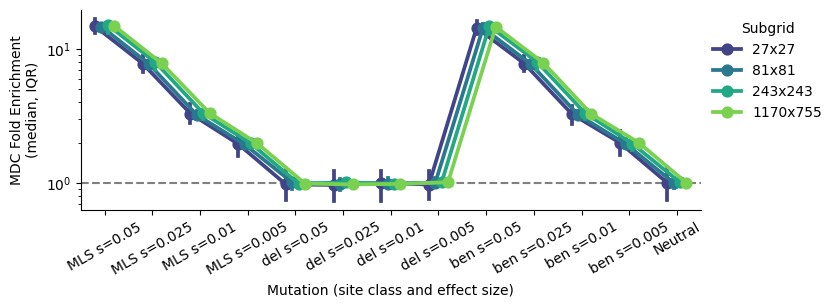

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.replace([np.inf, -np.inf], np.nan),
    x="mutation",
    y="fold_enrichment",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    _ax.axhline(1, color="gray", linestyle="--", zorder=0)
    _ax.set_yscale("log")
    _ax.set_xlabel("Mutation (site class and effect size)")
    _ax.set_ylabel("MDC Fold Enrichment\n(median, IQR)")
    _ax.tick_params(axis="x", rotation=30)
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(8, 2.6)

teeplots/2026-10-22-mls-spectra-subgrid-fossils/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.png


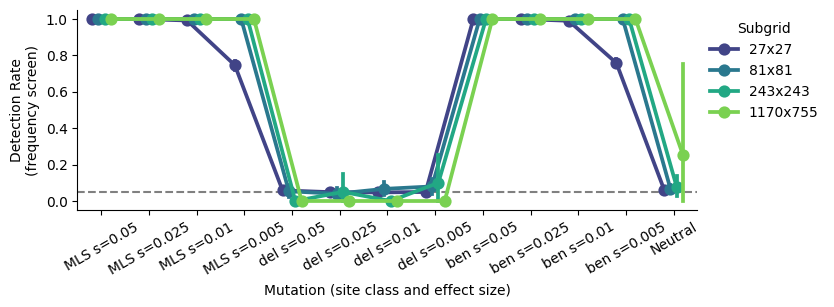

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.astype({"detected": float}),
    x="mutation",
    y="detected",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    errorbar=("ci", 95),
    n_boot=1000,
    seed=SEED,
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order", "seed"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    _ax.axhline(ALPHA, color="gray", linestyle="--", zorder=0)
    _ax.set_ylim(-0.05, 1.05)
    _ax.set_xlabel("Mutation (site class and effect size)")
    _ax.set_ylabel("Detection Rate\n(frequency screen)")
    _ax.tick_params(axis="x", rotation=30)
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(8, 2.6)

## Clade-fitness Screen

Within each population, each MDC's size (`carriers`) and clade duration are percentile-ranked (mean rank for ties) against comparator MDCs: the pooled MDCs of background (neutral) sites in the same population, drawn from the same MDC subset.
Under the `epoch100` normalization, comparison is further restricted to comparators originating within the same 100-update `origin_time` bin, controlling for recency bias.

For each population and site, a one-sided Mann-Whitney U test asks whether the site's MDC percentiles are lower than those of background MDCs (excluding the site itself, for neutral control sites).
MLS predicts lower percentiles.

MDC subsets are `all` MDCs, `inner` (excluding terminal-branch MDCs), and `inner_f75` (non-terminal MDCs with at least 75% carriers).

In [ ]:
subsets = {
    "all": lambda df: np.ones(len(df), dtype=bool),
    "inner": lambda df: ~df["is_terminal"].to_numpy(),
    "inner_f75": lambda df: (
        ~df["is_terminal"].to_numpy()
        & (df["carrier_frac"].to_numpy() >= 0.75)
    ),
}

In [ ]:
normalizations = {"all": None, "epoch100": 100}
stat_cols = ("carriers", "clade_duration")
_parts = []
for _subset, _subset_mask in subsets.items():
    _data = mdcs[_subset_mask(mdcs)]
    _comparator = ~_data["is_focal"].to_numpy()
    _keep = ~_comparator | _data["is_control"].to_numpy()
    for _norm, _binwidth in normalizations.items():
        _epoch = (
            np.zeros(len(_data), dtype=np.int64)
            if _binwidth is None
            else (_data["origin_time"].to_numpy() // _binwidth).astype(
                np.int64
            )
        )
        _groups = _data["pop_code"].to_numpy() * 2**16 + _epoch
        for _stat in stat_cols:
            _parts.append(
                _data[
                    ["pop_code", "site", "is_focal", "is_control"]
                ].assign(
                    subset=_subset,
                    normalization=_norm,
                    stat=_stat,
                    percentile=percentileofscore_grouped(
                        _data[_stat].to_numpy(dtype=float),
                        _groups,
                        _comparator,
                    ),
                ),
            )
normed = pd.concat(_parts, ignore_index=True).dropna(subset=["percentile"])

In [ ]:
_records = []
_tested_sites = [*focal_sites, *control_sites]
for (_pop, _subset, _norm, _stat), _group in mo.status.progress_bar(
    normed.groupby(
        ["pop_code", "subset", "normalization", "stat"], sort=False
    ),
):
    _sites = _group["site"].to_numpy()
    _pct = _group["percentile"].to_numpy()
    _is_bg = ~_group["is_focal"].to_numpy()
    for _site in _tested_sites:
        _in_site = _sites == _site
        _x = _pct[_in_site]
        _y = _pct[_is_bg & ~_in_site]
        if not len(_x) or not len(_y):
            continue
        _mw_u, _mw_p = scipy_stats.mannwhitneyu(_x, _y, alternative="less")
        _records.append(
            {
                "pop_code": _pop,
                "subset": _subset,
                "normalization": _norm,
                "stat": _stat,
                "site": _site,
                "n_site": len(_x),
                "n_background": len(_y),
                "site_mean_pct": _x.mean(),
                "p_mw_less": _mw_p,
                "cliffs_delta": 2 * _mw_u / (len(_x) * len(_y)) - 1,
            },
        )
fitness_screen = pd.DataFrame(_records)

In [ ]:
# one row per screened (population, site), including those with no MDCs
# in subset, which count as not detected
_pop_sites = freq_screen[["pop_code", "site", "mutation"]]
fitness_detection = (
    fitness_screen[["subset", "normalization", "stat"]]
    .drop_duplicates()
    .merge(_pop_sites, how="cross")
    .merge(
        fitness_screen,
        on=["pop_code", "site", "subset", "normalization", "stat"],
        how="left",
    )
    .merge(populations[["pop_code", "pop_size", "pop_tiles"]])
)
fitness_detection["is_control"] = fitness_detection["site"].isin(
    control_sites
)
fitness_detection["detected"] = fitness_detection["p_mw_less"] < ALPHA
fitness_detection.groupby(
    ["subset", "normalization", "stat", "pop_size", "mutation"],
    sort=False,
).agg(
    num_populations=("pop_code", "nunique"),
    num_screened=("p_mw_less", "count"),
    n_site_mean=("n_site", "mean"),
    site_mean_pct_mean=("site_mean_pct", "mean"),
    cliffs_delta_mean=("cliffs_delta", "mean"),
    detection_rate=("detected", "mean"),
).unstack(
    "pop_size"
)

num_populations num_screened n_site_mean ... site_mean_pct_mean cliffs_delta_mean detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 subset normalization stat mutation all all carriers ben s=0.05 1 1232 150 20 1 1232 150 20 177277.00 134.346591 ... 62.537265 65.137755 0.227486 0.232211 0.250745 0.302755 0.0 0.000000 0.000000 0.0000 ben s=0.025 1 1232 150 20 1 1232 150 20 95175.00 72.922890 ... 61.226159 63.163414 0.200564 0.205595 0.224523 0.263268 0.0 0.000000 0.000000 0.0000 ben s=0.01 1 1232 150 20 1 1232 150 20 39694.00 30.302760 ... 58.101017 59.156187 0.150075 0.151546 0.162020 0.183124 0.0 0.002435 0.000000 0.0000 ben s=0.005 1 1232 150 20 1 1232 150 20 24169.00 18.737013 ... 55.133384 56.134517 0.099788 0.099399 0.102668 0.122690 0.0 0.009740 0.000000 0.0000 MLS s=0.05 1 1232 150 20 1 1232 150 20 180207.00 136.971591 ... 62.750274 65.304092 0.230234 0.232828 0.255005 0.306082 0.0 0.000000 0.000000 0.0000 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... inner_f75 epoch100 clade_duration del s=0.05 1 1232 150 20 1 936 150 20 5976.00 1.997863 ... 49.408600 50.304106 -0.003644 -0.020753 -0.012322 0.006006 0.0 0.235390 0.133333 0.0000 del s=0.025 1 1232 150 20 1 938 150 20 5890.00 1.985075 ... 48.959908 50.412422 0.013826 0.009042 -0.021123 0.008151 0.0 0.213474 0.100000 0.1000 del s=0.01 1 1232 150 20 1 954 150 20 5852.00 1.945493 ... 49.427976 50.729200 -0.003975 -0.023903 -0.011900 0.014516 0.0 0.244318 0.153333 0.0000 del s=0.005 1 1232 150 20 1 952 150 20 6102.00 1.928571 ... 50.009942 49.935891 0.005999 -0.024095 0.000816 -0.001426 0.0 0.241071 0.126667 0.1000 Neutral 1 1232 150 20 4 4877 600 80 6084.25 4.935206 ... 50.040165 49.976015 0.000023 0.001957 0.000806 -0.000443 0.0 0.035106 0.058333 0.0375 156 rows × 24 columns

teeplots/2026-10-22-mls-spectra-subgrid-fossils/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.png


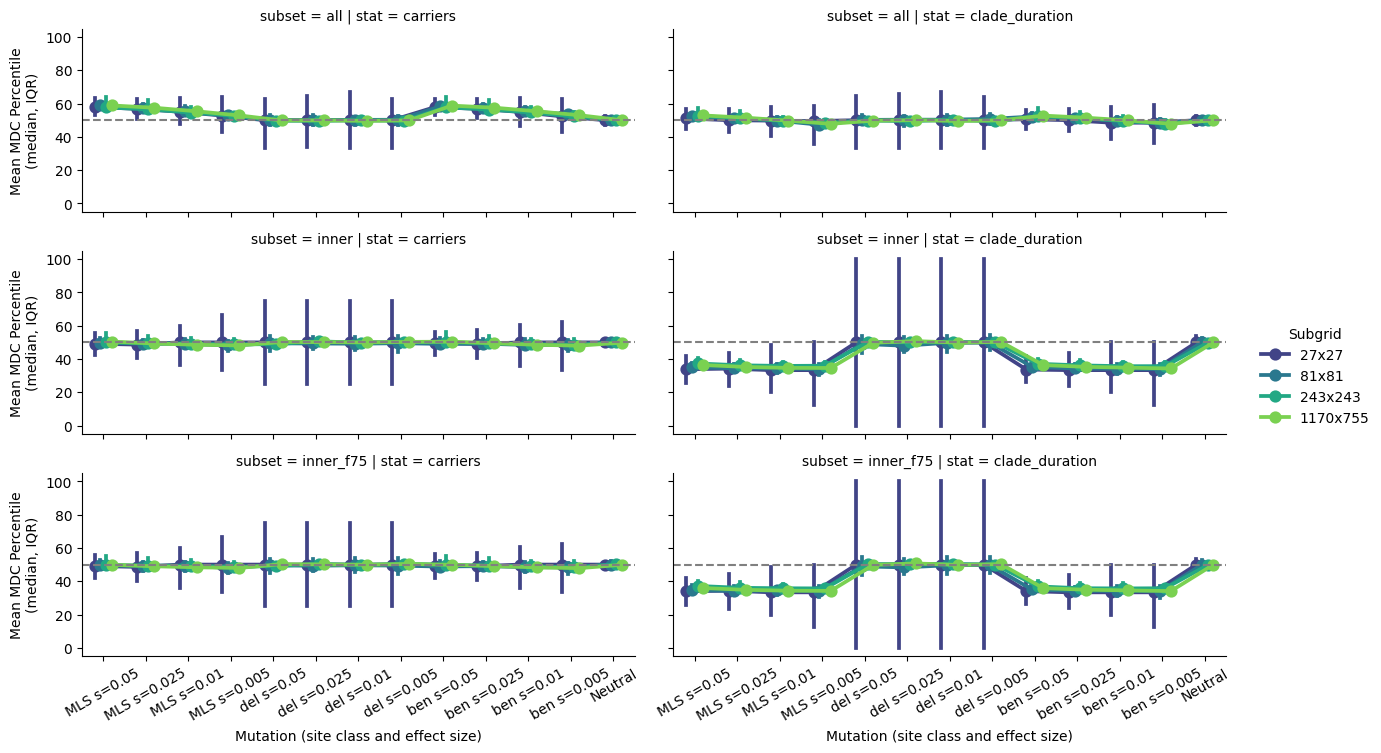

In [ ]:
with tp.teed(
    sns.catplot,
    data=fitness_detection[
        fitness_detection["normalization"] == "epoch100"
    ].dropna(subset=["site_mean_pct"]),
    x="mutation",
    y="site_mean_pct",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    col="stat",
    row="subset",
    kind="point",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    height=2.4,
    aspect=2.6,
    teeplot_outattrs={"normalization": "epoch100"},
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.refline(y=50, color="gray", linestyle="--")
    _g.set_axis_labels(
        "Mutation (site class and effect size)",
        "Mean MDC Percentile\n(median, IQR)",
    )
    _g.tick_params(axis="x", rotation=30)
    _g.legend.set_title("Subgrid")

teeplots/2026-10-22-mls-spectra-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


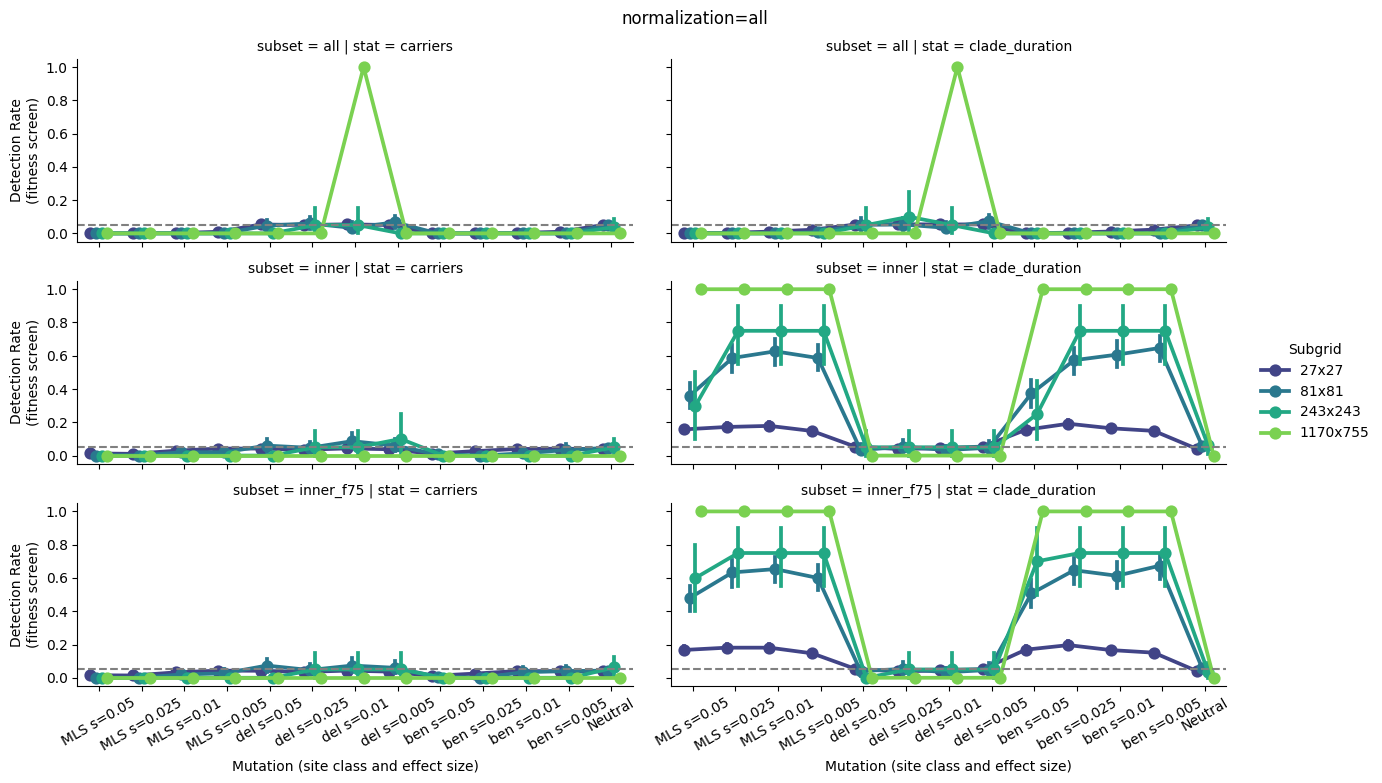

teeplots/2026-10-22-mls-spectra-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


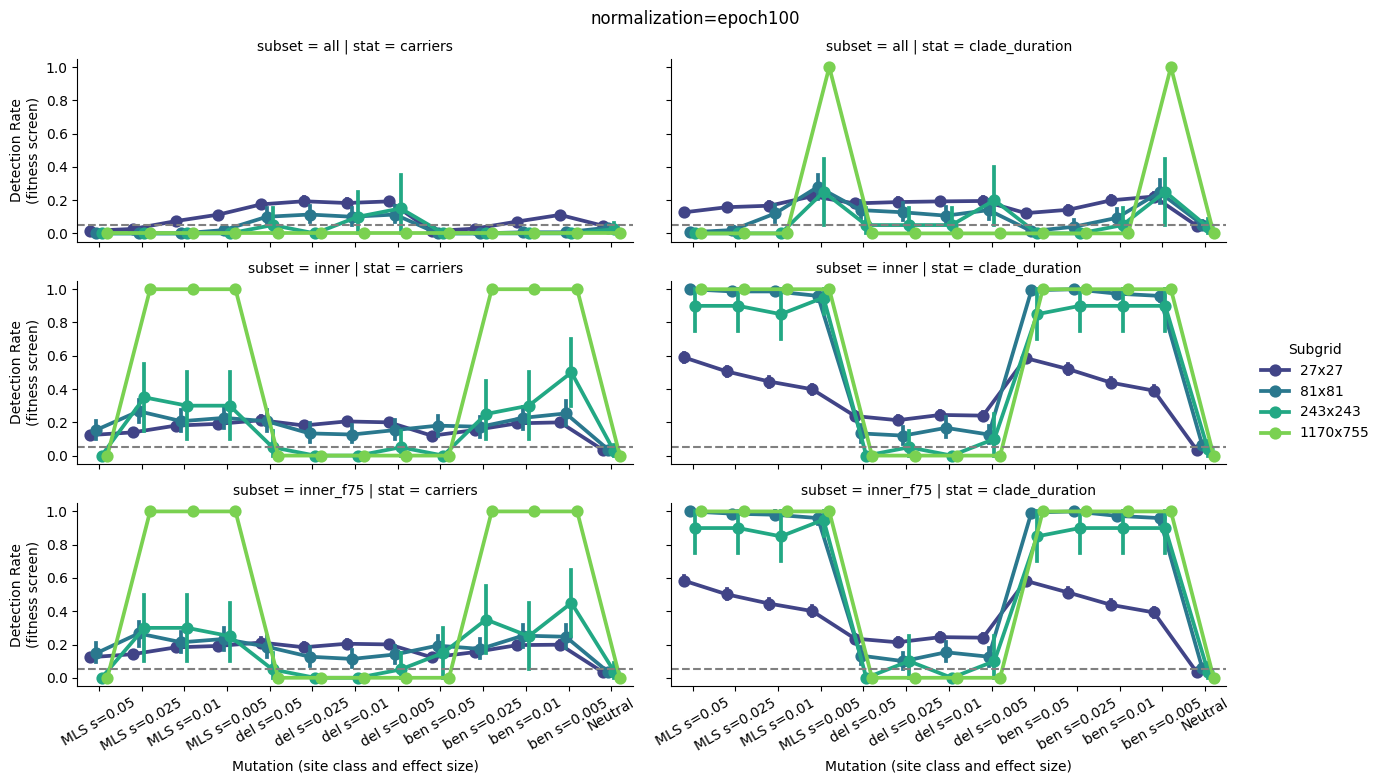

In [ ]:
for _norm in "all", "epoch100":
    with tp.teed(
        sns.catplot,
        data=fitness_detection[
            fitness_detection["normalization"] == _norm
        ].astype({"detected": float}),
        x="mutation",
        y="detected",
        order=mutation_order,
        hue="pop_size",
        hue_order=pop_size_order,
        palette="viridis",
        col="stat",
        row="subset",
        kind="point",
        errorbar=("ci", 95),
        n_boot=1000,
        seed=SEED,
        dodge=0.4,
        height=2.4,
        aspect=2.6,
        teeplot_outattrs={"normalization": _norm},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "dodge",
            "order",
            "seed",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        _g.set(ylim=(-0.05, 1.05))
        _g.set_axis_labels(
            "Mutation (site class and effect size)",
            "Detection Rate\n(fitness screen)",
        )
        _g.tick_params(axis="x", rotation=30)
        _g.legend.set_title("Subgrid")
        _g.figure.suptitle(f"normalization={_norm}", y=1.02)
    plt.close("all")

In [ ]:
mo.md(f"""
## Detectability Summary

Fraction of populations in which each screen detects each site at $\\alpha = {ALPHA}$, by population size (rows) and site class and effect size (columns).
The `Neutral` column gives the false positive rate over neutral control sites, and should sit near {ALPHA}.
Fitness screens shown use `epoch100` normalization.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per fossil layer and subgrid), so population size and sample size are confounded here.
The full grid is a single population, so its detection rates are each 0 or 1.
""")

## Detectability Summary

Fraction of populations in which each screen detects each site at $\alpha = 0.05$, by population size (rows) and site class and effect size (columns).
The `Neutral` column gives the false positive rate over neutral control sites, and should sit near 0.05.
Fitness screens shown use `epoch100` normalization.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per fossil layer and subgrid), so population size and sample size are confounded here.
The full grid is a single population, so its detection rates are each 0 or 1.

In [ ]:
_screens = {
    "frequency": freq_screen,
    **{
        f"fitness {_stat} {_subset}": fitness_detection[
            (fitness_detection["normalization"] == "epoch100")
            & (fitness_detection["stat"] == _stat)
            & (fitness_detection["subset"] == _subset)
        ]
        for _stat in ("carriers", "clade_duration")
        for _subset in ("all", "inner_f75")
    },
}
detectability = pd.concat(
    [
        _df.groupby(["pop_size", "mutation"], as_index=False)
        .agg(
            detection_rate=("detected", "mean"),
            num_screened=("detected", "size"),
        )
        .assign(screen=_screen)
        for _screen, _df in _screens.items()
    ],
    ignore_index=True,
)
detectability.pivot_table(
    index=["screen", "pop_size"],
    columns="mutation",
    values="detection_rate",
    sort=False,
)

mutation MLS s=0.005 MLS s=0.01 MLS s=0.025 MLS s=0.05 Neutral ben s=0.005 ben s=0.01 ben s=0.025 ben s=0.05 del s=0.005 del s=0.01 del s=0.025 del s=0.05 screen pop_size frequency 1170x755 1.000000 1.000000 1.000000 1.000000 0.250000 1.000000 1.000000 1.000000 1.000000 0.000000 0.000000 0.000000 0.000000 243x243 1.000000 1.000000 1.000000 1.000000 0.075000 1.000000 1.000000 1.000000 1.000000 0.100000 0.000000 0.050000 0.000000 27x27 0.745942 0.991883 1.000000 1.000000 0.062500 0.758117 0.990260 1.000000 1.000000 0.049513 0.047078 0.048701 0.058442 81x81 1.000000 1.000000 1.000000 1.000000 0.066667 1.000000 1.000000 1.000000 1.000000 0.080000 0.066667 0.040000 0.053333 fitness carriers all 1170x755 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... fitness clade_duration all 81x81 0.280000 0.120000 0.020000 0.006667 0.053333 0.246667 0.093333 0.040000 0.013333 0.140000 0.106667 0.126667 0.140000 fitness clade_duration inner_f75 1170x755 1.000000 1.000000 1.000000 1.000000 0.000000 1.000000 1.000000 1.000000 1.000000 0.000000 0.000000 0.000000 0.000000 243x243 0.950000 0.850000 0.900000 0.900000 0.037500 0.900000 0.900000 0.900000 0.850000 0.100000 0.000000 0.100000 0.000000 27x27 0.400974 0.445617 0.501623 0.583604 0.035106 0.392857 0.438312 0.512175 0.582792 0.241071 0.244318 0.213474 0.235390 81x81 0.960000 0.980000 0.986667 1.000000 0.058333 0.960000 0.973333 1.000000 0.993333 0.126667 0.153333 0.100000 0.133333 20 rows × 13 columns

teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=frequency+viz=heatmap+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=frequency+viz=heatmap+ext=.png


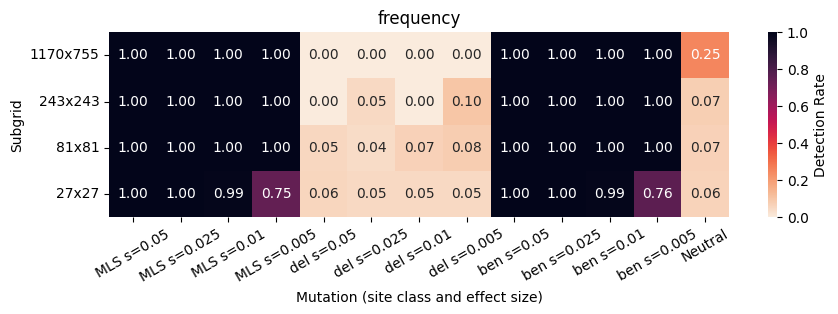

teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=fitness-carriers-all+viz=heatmap+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=fitness-carriers-all+viz=heatmap+ext=.png


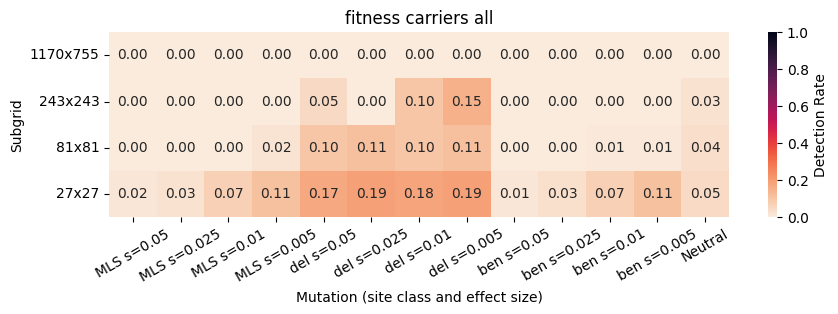

teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.png


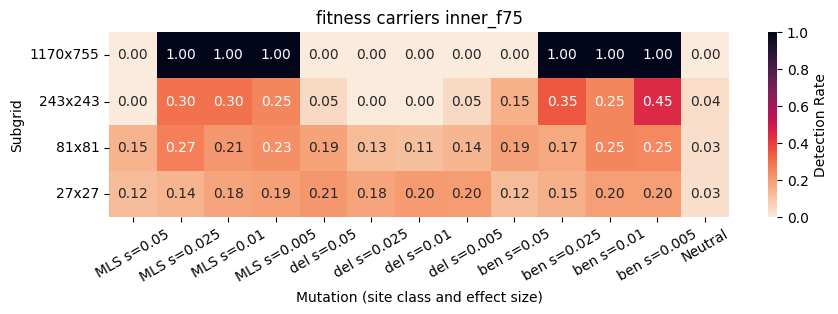

teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=fitness-clade_duration-all+viz=heatmap+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=fitness-clade_duration-all+viz=heatmap+ext=.png


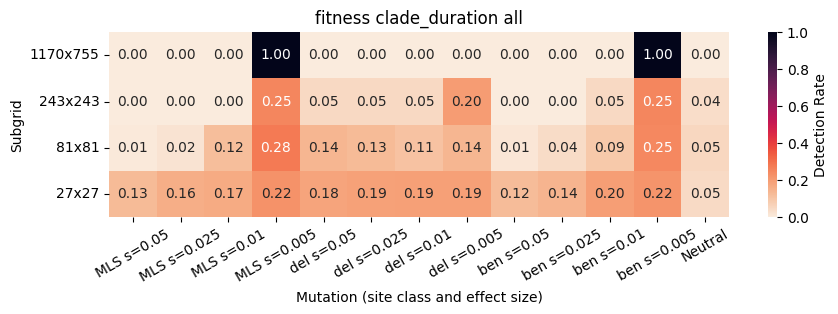

teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-22-mls-spectra-subgrid-fossils/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.png


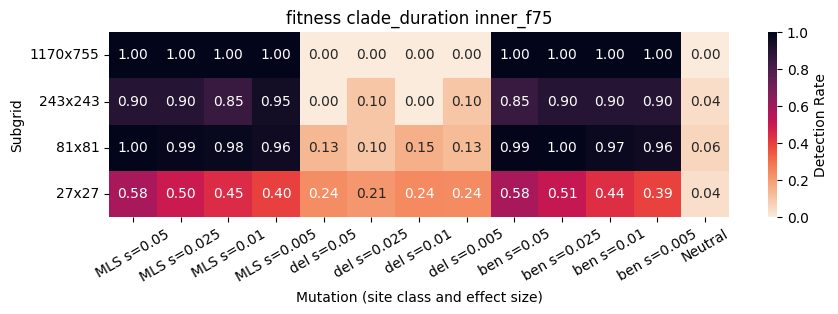

In [ ]:
for _screen, _df in detectability.groupby("screen", sort=False):
    _pivot = _df.pivot(
        index="pop_size", columns="mutation", values="detection_rate"
    ).reindex(index=pop_size_order[::-1], columns=mutation_order)
    with tp.teed(
        sns.heatmap,
        _pivot,
        annot=True,
        fmt=".2f",
        cmap="rocket_r",
        vmin=0,
        vmax=1,
        cbar_kws={"label": "Detection Rate"},
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=["annot", "fmt", "cmap", "vmin", "vmax"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _ax:
        _ax.set_xlabel("Mutation (site class and effect size)")
        _ax.set_ylabel("Subgrid")
        _ax.set_title(_screen)
        _ax.tick_params(axis="x", rotation=30)
        _ax.tick_params(axis="y", rotation=0)
        _ax.figure.set_size_inches(10, 2.4)
    plt.close("all")